In [ ]:
import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from matplotlib.colors import ListedColormap
from scipy.stats import ttest_rel, wilcoxon
from sklearn.datasets import make_regression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import Lasso, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [ ]:
engines = pd.read_csv('EngineFaultDB_Final.csv')

In [5]:
engines.describe()

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
count,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000
mean,1.482187,1.832515,1.395269,286.691705,5.657126,2398.053774,4.497634,8.939794,51.688740,1.932430,188.446083,13.035230,0.585910,0.963907,14.169408
std,1.149430,0.837786,0.906950,378.774917,7.684147,932.008680,2.221497,3.154110,20.140345,1.988789,111.047015,1.046567,0.223713,0.065973,0.969802
min,0.000000,0.453000,0.382000,2.580000,0.465000,1066.452000,1.917000,5.187000,22.757000,0.421000,1.787000,8.649000,0.203000,0.695000,10.210000
25%,0.000000,1.217000,0.901000,76.848500,0.994000,1830.200500,2.981000,6.573000,39.412000,0.641000,158.803000,12.842000,0.415000,0.937000,13.780000
50%,2.000000,1.543000,1.013000,92.500000,2.398000,2105.588000,3.824000,8.068000,45.393000,1.129000,178.265000,13.242000,0.533000,0.977000,14.365000
75%,3.000000,1.940000,1.258000,257.989500,4.696000,2761.373500,5.144500,9.924000,59.508000,2.455000,203.678000,13.639000,0.789000,1.008000,14.823000
max,3.000000,4.547000,4.048000,1537.118000,33.946000,5013.402000,14.810000,20.043000,107.539000,10.132000,975.657000,15.129000,1.151000,1.149000,16.893000


In [6]:
engines.dtypes

Fault                    int64
MAP                    float64
TPS                    float64
Force                  float64
Power                  float64
RPM                    float64
Consumption L/H        float64
Consumption L/100KM    float64
Speed                  float64
CO                     float64
HC                     float64
CO2                    float64
O2                     float64
Lambda                 float64
AFR                    float64
dtype: object

In [7]:
engines.shape

(55999, 15)

In [8]:
engines.isnull().sum() # no missing data

Fault                  0
MAP                    0
TPS                    0
Force                  0
Power                  0
RPM                    0
Consumption L/H        0
Consumption L/100KM    0
Speed                  0
CO                     0
HC                     0
CO2                    0
O2                     0
Lambda                 0
AFR                    0
dtype: int64

In [9]:
engines.Fault.unique()

array([0, 1, 2, 3])

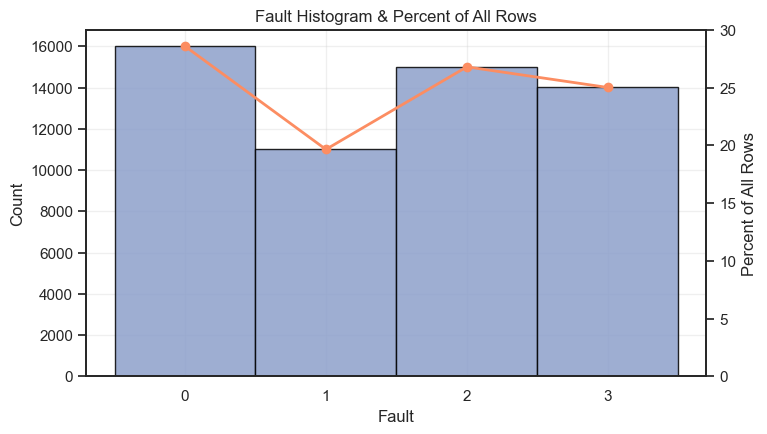

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

s = engines["Fault"].dropna()

# discrete values (e.g., 1..4)
vals = sorted(s.unique())
counts = s.value_counts().reindex(vals).fillna(0).astype(int)

# percent out of all rows (not cumulative)
pct = counts / counts.sum() * 100

# histogram-like bars (counts) + percentage labels/line on same x
bins = [v - 0.5 for v in vals] + [vals[-1] + 0.5]

sns.set_theme(style="white", palette="Set2")
bar_color = sns.color_palette("Set2")[2]
line_color = sns.color_palette("Set2")[1]

fig, ax1 = plt.subplots(figsize=(8, 4.5))

# histogram bars (counts)
ax1.hist(s, bins=bins, edgecolor="black", alpha=0.85, color=bar_color)
ax1.set_xticks(vals)
ax1.set_xlabel("Fault")
ax1.set_ylabel("Count")

# percentage line (percent of all rows)
ax2 = ax1.twinx()
ax2.plot(vals, pct.values, marker="o", linewidth=2, color=line_color)
ax2.set_ylabel("Percent of All Rows")
ax2.set_ylim(0, max(10, float(np.ceil(pct.max()/5)*5)))  # reasonable top

ax1.set_title("Fault Histogram & Percent of All Rows")
ax1.grid(True, alpha=0.3)

plt.show()


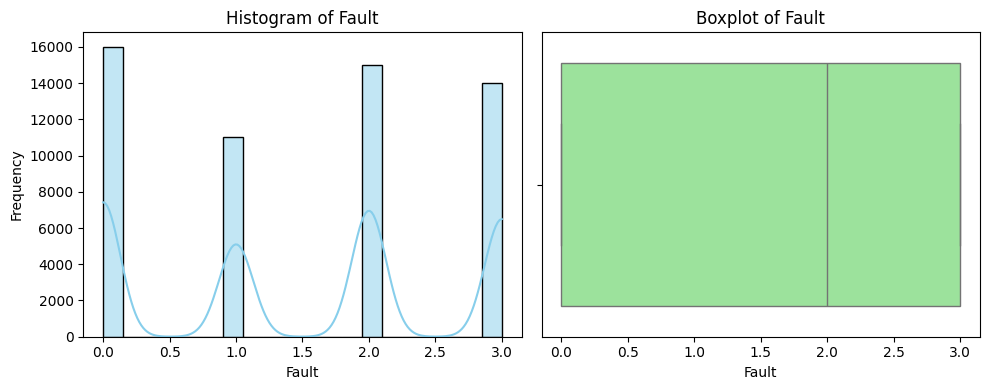

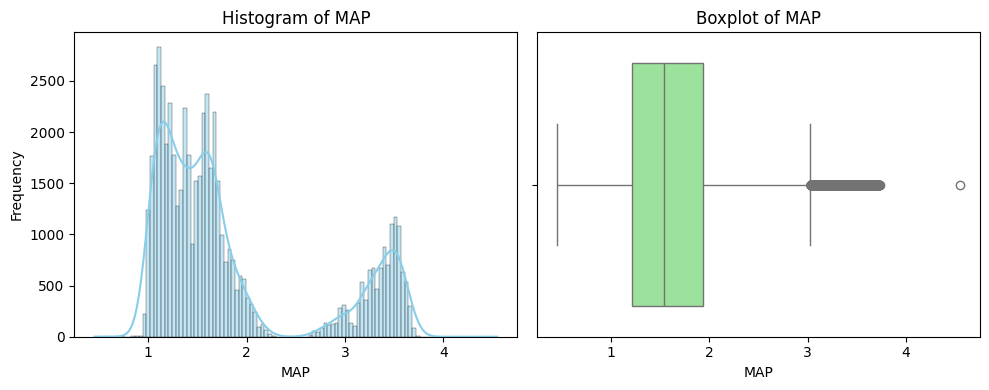

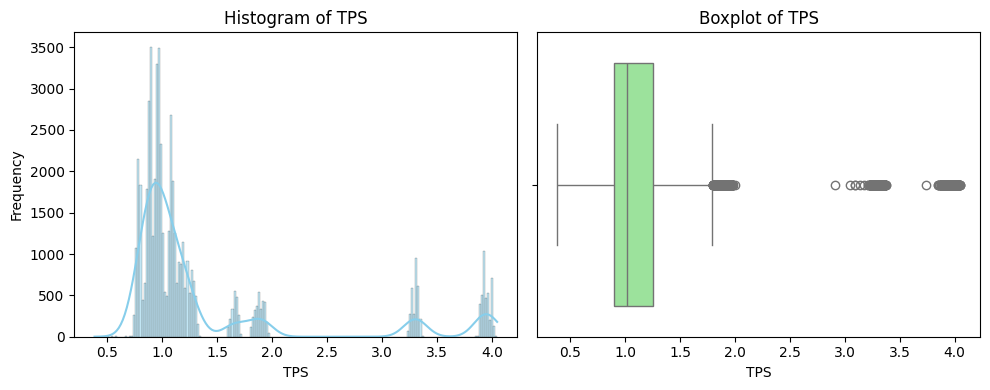

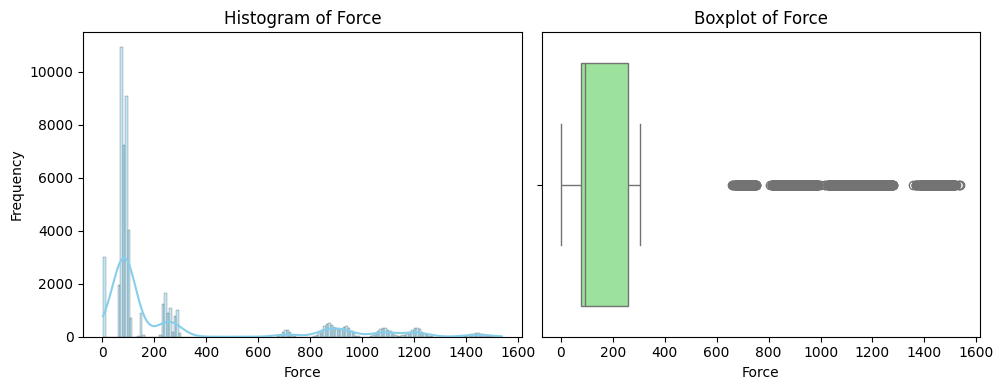

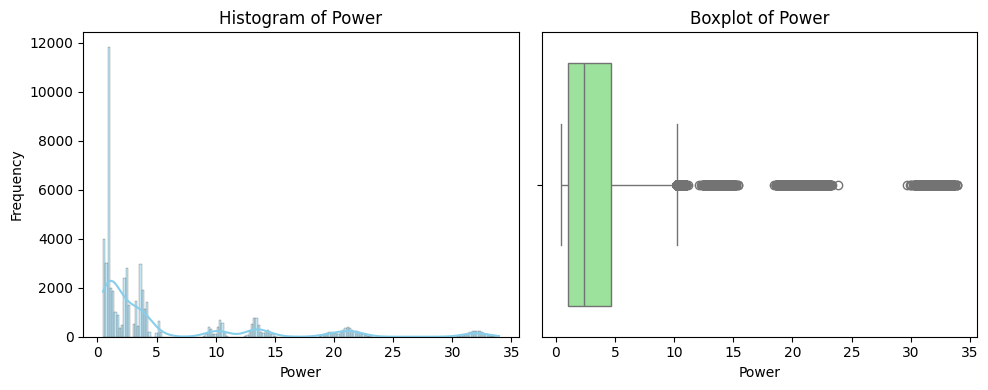

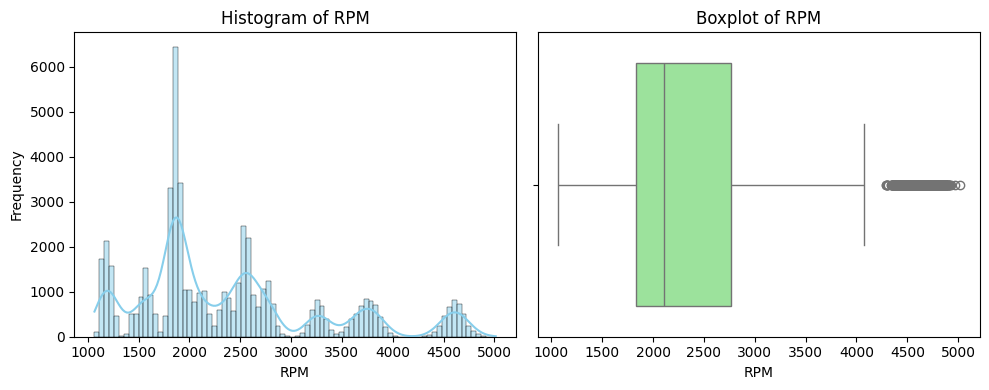

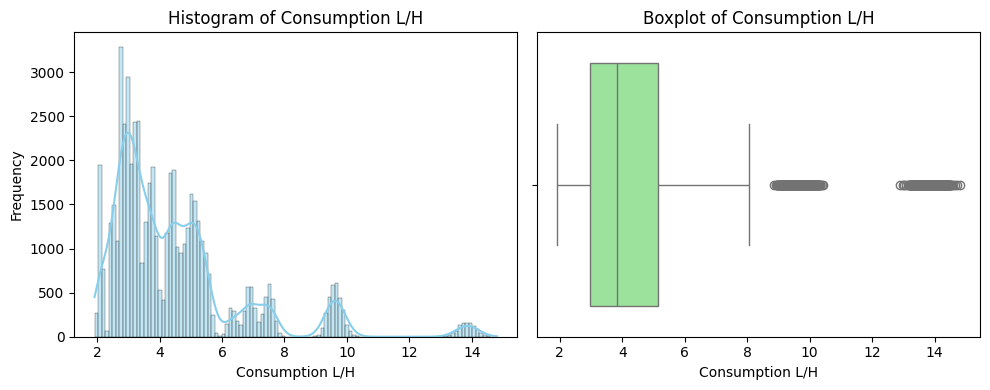

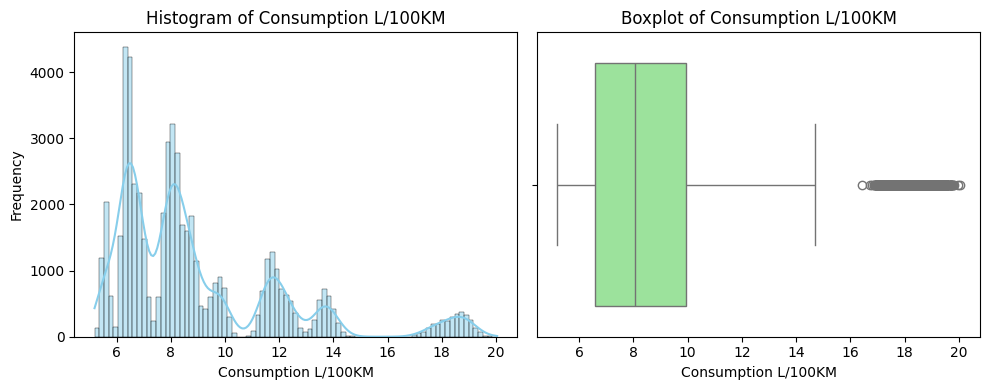

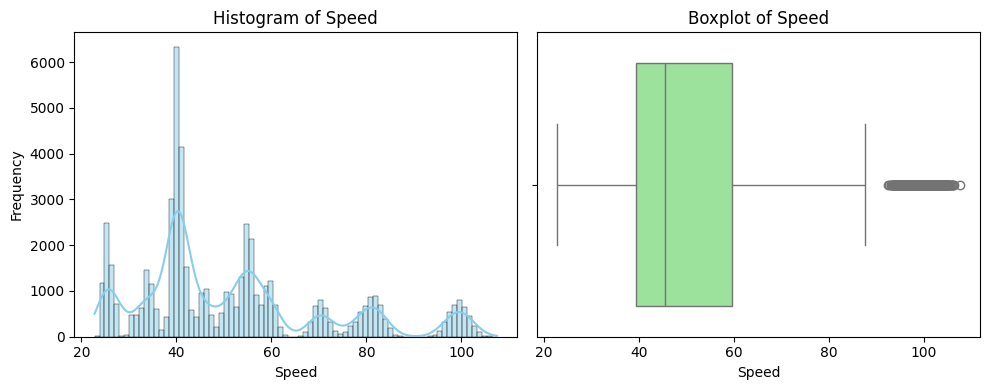

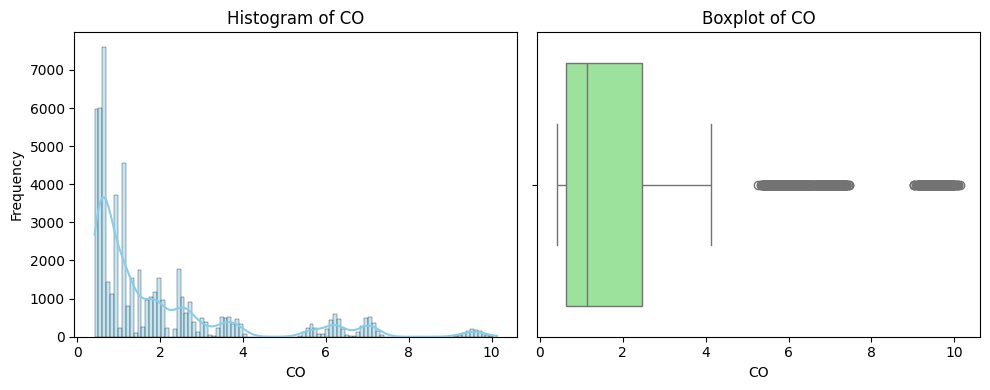

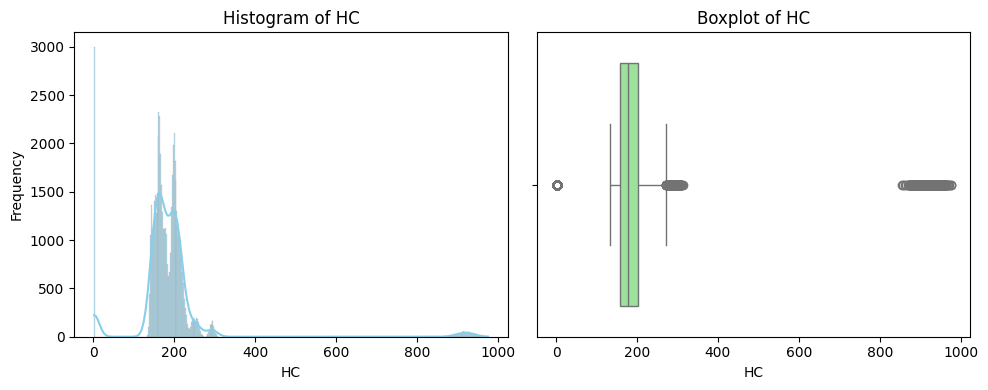

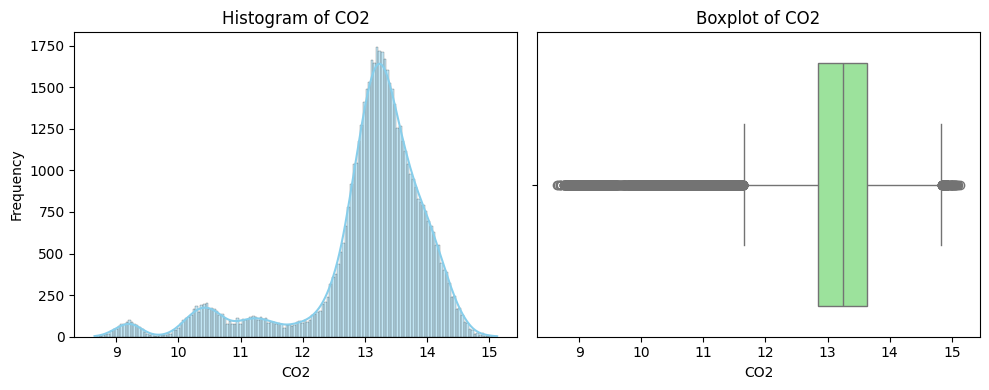

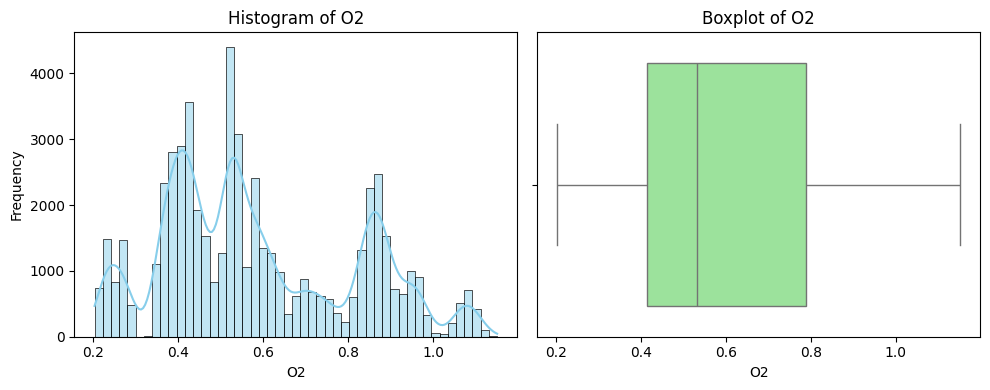

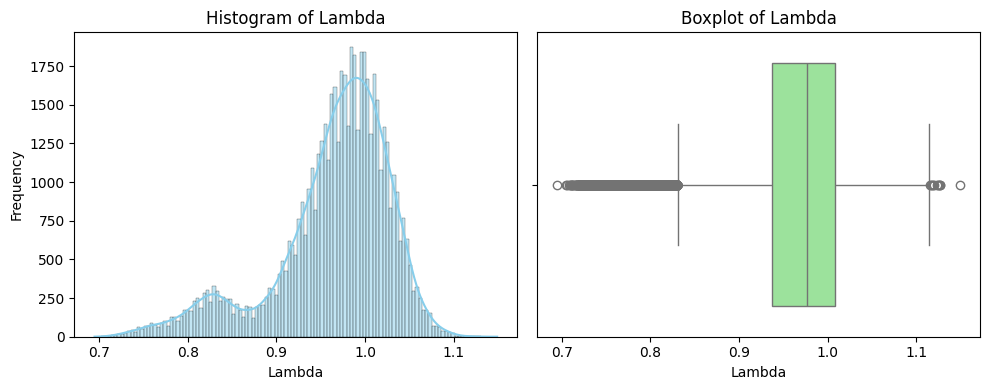

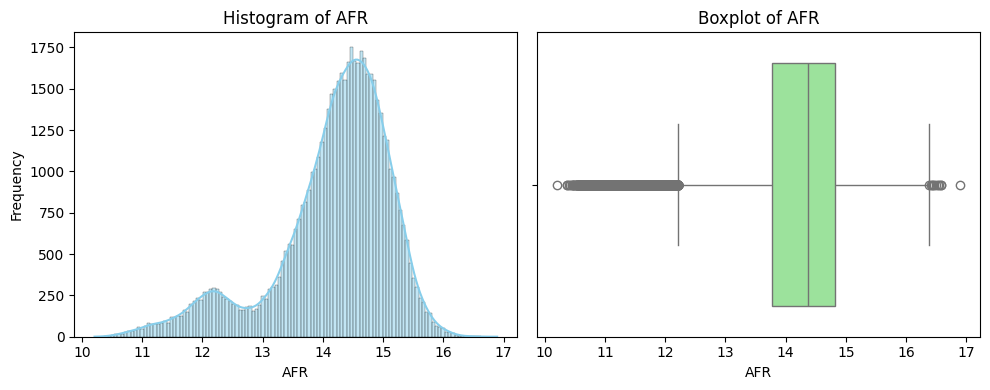

In [10]:
for col in engines.columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # Histogram
    sns.histplot(engines[col].dropna(), kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histogram of {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')
    
    # Boxplot
    sns.boxplot(x=engines[col], ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot of {col}')
    axes[1].set_xlabel(col)
    
    plt.tight_layout()
    plt.show()

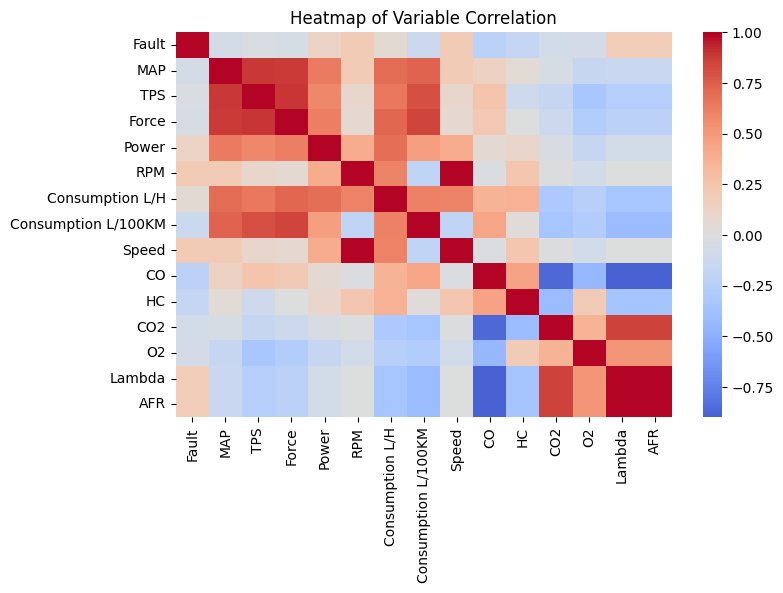

In [152]:
corr = engines.corr()
plt.figure(figsize=(8,5))
plt.title('Heatmap of Variable Correlation')
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

In [12]:
# use VIF to check multicollinearity
# add constant for statsmodels
X_const = sm.add_constant(engines.iloc[:,1:])

vif_df_feature_selection = pd.DataFrame()
vif_df_feature_selection["variable"] = X_const.columns
vif_df_feature_selection["VIF"] = [variance_inflation_factor(X_const.values, i)
                 for i in range(X_const.shape[1])]
vif_df_feature_selection = vif_df_feature_selection[vif_df_feature_selection["variable"] != "const"]
print(vif_df_feature_selection.sort_values("VIF", ascending=False).head())

# VIF<3 -> no multicollinearity
# VIF 3-5 -> moderate
# VIF>5 -> high
def vif_categorizer(x):
    if x<=1:
        return 'none'
    if x>1 and x<=5:
        return 'moderate'
    if x>5:
        return 'high'
vif_df_feature_selection['multicollinearity'] = vif_df_feature_selection['VIF'].apply(lambda x: vif_categorizer(x))
vif_df_feature_selection.sort_values('VIF', ascending=False)

           variable           VIF
14              AFR  52064.931965
13           Lambda  52057.734318
5               RPM    168.748555
8             Speed    164.461881
6   Consumption L/H     36.357656


,variable,VIF,multicollinearity
14,AFR,52064.931965,high
13,Lambda,52057.734318,high
5,RPM,168.748555,high
8,Speed,164.461881,high
6,Consumption L/H,36.357656,high
7,Consumption L/100KM,25.763986,high
3,Force,11.245738,high
1,MAP,8.618050,high
2,TPS,8.571702,high
9,CO,8.489502,high


In [13]:
# generate synthetic data
X = engines.iloc[:,1:]
y = engines.iloc[:,0]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)
# ridge regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
# lasso regression
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
df_feature_selection = pd.DataFrame()
df_feature_selection['Variable'] = X.columns
df_feature_selection["Ridge Coefficients"] = ridge.coef_
df_feature_selection['LASSO Coefficients'] = lasso.coef_

In [14]:
df_feature_selection.sort_values(by='Ridge Coefficients')
# deciding on ridge to avoid sparsity
#.1 * max(ridge coeff) = .142 -> used as threshold to keep variables

,Variable,Ridge Coefficients,LASSO Coefficients
10,CO2,-1.429820,-0.663214
11,O2,-1.018197,-0.000000
8,CO,-0.459436,-0.345425
6,Consumption L/100KM,-0.232141,-0.000000
0,MAP,-0.172101,-0.000000
7,Speed,-0.023660,-0.000000
9,HC,-0.002635,-0.002210
2,Force,-0.000158,-0.000231
4,RPM,0.000023,0.000240
3,Power,0.011600,0.016308


In [15]:
selected_features = df_feature_selection[(df_feature_selection['Ridge Coefficients']>.142) | (df_feature_selection['Ridge Coefficients']<-.142)].Variable

In [16]:
# engine characteristics only X
engine_characteristics = ['MAP', 'TPS', 'Force', 'Power', 'RPM', 'Consumption L/H', 'Consumption L/100KM', 'Speed']
engines_1 = engines[engine_characteristics]

# exhaust only X
exhaust_characteristics = ['CO', 'HC', 'CO2', 'O2', 'Lambda', 'AFR']
engines_2 = engines[exhaust_characteristics]

# variable selected X
engines_3 = engines[selected_features]

In [ ]:
def model_results(X, best_k):
    Ni = X.shape[1]      # number of input features (should be 14)
    No = len(np.unique(y))  # number of output classes (should be 4)
    Nh = int(0.5 * (Ni + No))  # Piramuthu rule → 9 neurons

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    #  BEST-K SEARCH FOR KNN (K = 1 → 25)
    best_k = None
    best_k_score = -1
    for k in range(1, 26):
        knn_model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=k))
        ])
        scores = cross_val_score(knn_model, X, y, cv=cv, scoring="accuracy")
        mean_score = scores.mean()

        if mean_score > best_k_score:
            best_k_score = mean_score
            best_k = k

    print(f"Best K found: {best_k} with accuracy={best_k_score:.4f}")

    #  FEED-FORWARD NN USING PURE SCIKIT-LEARN (MLPClassifier)
    ffnn_clf = MLPClassifier(
        hidden_layer_sizes=(Nh,),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=100,
        batch_size=64,
        early_stopping=True,
        n_iter_no_change=5,
        random_state=123
    )

    #  MODELS DICTIONARY
    models = {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=500))
        ]),
        "Decision Tree": DecisionTreeClassifier(random_state=123),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=123),
        "SVC": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", probability=False, random_state=123))
        ]),
        "Best-K KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=best_k))
        ]),
        "Naive Bayes": GaussianNB(),
        "Feed-Forward NN (Piramuthu Rule)": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", ffnn_clf)
        ]),
        "QDA": QuadraticDiscriminantAnalysis(),
        "LDA": LinearDiscriminantAnalysis(),
        "Gradient Boosting": GradientBoostingClassifier(random_state=123)
    }

    #  SCORING METRICS
    scoring = {
        "accuracy": "accuracy",
        "precision": 'precision_macro',
        "recall": 'recall_macro',
        "f1": 'f1_macro'
    }

    #  CROSS-VALIDATION FOR ALL MODELS
    results = {}
    results_long = {}

    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True)
        results[name] = {
            "train_accuracy": scores["train_accuracy"].mean(),
            "accuracy": scores["test_accuracy"].mean(),
            "precision": scores["test_precision"].mean(),
            "recall": scores["test_recall"].mean(),
            "f1": scores["test_f1"].mean()
        }
        results_long[name] = scores['test_f1']

        print(name, ' done')
    #  PRINT RESULTS
        for name, metrics in results.items():
            print(f"\n{name}")
            print(f"  Train Acc : {metrics['train_accuracy']:.4f}")
            print(f"  Val Acc   : {metrics['accuracy']:.4f}")
            print(f"  Precision : {metrics['precision']:.4f}")
            print(f"  Recall    : {metrics['recall']:.4f}")
            print(f"  F1        : {metrics['f1']:.4f}")
    return results, results_long

engines_1_results, engines_1_results_long = model_results(engines_1,4)
engines_2_results, engines_2_results_long = model_results(engines_2,3)
engines_3_results, engines_3_results_long = model_results(engines_3,23)

Logistic Regression  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705
Decision Tree  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526
Random Forest  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526

Random Forest
  Train Acc : 1.0000
  Val Acc   : 0.7422
  Precision : 0.7498
  Recall    : 0.7500
  F1        : 0.7498
SVC  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  P

C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classificati

Naive Bayes  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526

Random Forest
  Train Acc : 1.0000
  Val Acc   : 0.7422
  Precision : 0.7498
  Recall    : 0.7500
  F1        : 0.7498

SVC
  Train Acc : 0.6952
  Val Acc   : 0.6859
  Precision : 0.7039
  Recall    : 0.6924
  F1        : 0.6899

Best-K KNN
  Train Acc : 0.8370
  Val Acc   : 0.7393
  Precision : 0.7421
  Recall    : 0.7436
  F1        : 0.7348

Naive Bayes
  Train Acc : 0.3472
  Val Acc   : 0.3463
  Precision : 0.2956
  Recall    : 0.3286
  F1        : 0.2758
Feed-Forward NN (Piramuthu Rule)  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1   

C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
C:\Users\nicol\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing 

QDA  done

Logistic Regression
  Train Acc : 0.5283
  Val Acc   : 0.5282
  Precision : 0.5568
  Recall    : 0.5018
  F1        : 0.4898

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7458
  Precision : 0.7542
  Recall    : 0.7541
  F1        : 0.7542

Random Forest
  Train Acc : 1.0000
  Val Acc   : 0.7455
  Precision : 0.7538
  Recall    : 0.7538
  F1        : 0.7538

SVC
  Train Acc : 0.6986
  Val Acc   : 0.6914
  Precision : 0.6989
  Recall    : 0.6977
  F1        : 0.6911

Best-K KNN
  Train Acc : 0.8763
  Val Acc   : 0.7493
  Precision : 0.7575
  Recall    : 0.7575
  F1        : 0.7575

Naive Bayes
  Train Acc : 0.4329
  Val Acc   : 0.4338
  Precision : 0.4533
  Recall    : 0.4192
  F1        : 0.4181

Feed-Forward NN (Piramuthu Rule)
  Train Acc : 0.5579
  Val Acc   : 0.5570
  Precision : 0.6070
  Recall    : 0.5333
  F1        : 0.5166

QDA
  Train Acc : 0.5241
  Val Acc   : 0.5238
  Precision : 0.5208
  Recall    : 0.5072
  F1        : 0.4820
LDA  done

Logistic Regression

In [19]:
engines_1_results

{'Logistic Regression': {'train_accuracy': np.float64(0.3895158868342087),
  'accuracy': np.float64(0.3871142177873025),
  'precision': np.float64(0.4004698201886258),
  'recall': np.float64(0.397084620091687),
  'f1': np.float64(0.3705174380533227)},
 'Decision Tree': {'train_accuracy': np.float64(1.0),
  'accuracy': np.float64(0.7449775840955187),
  'precision': np.float64(0.7527346878670744),
  'recall': np.float64(0.7524872532124898),
  'f1': np.float64(0.7525930725235115)},
 'Random Forest': {'train_accuracy': np.float64(1.0),
  'accuracy': np.float64(0.7422274804510607),
  'precision': np.float64(0.7497569043899533),
  'recall': np.float64(0.7500174681559498),
  'f1': np.float64(0.749754964464398)},
 'SVC': {'train_accuracy': np.float64(0.6951686661731926),
  'accuracy': np.float64(0.6859408429324046),
  'precision': np.float64(0.7039427758675617),
  'recall': np.float64(0.6923778423929716),
  'f1': np.float64(0.6898603303012971)},
 'Best-K KNN': {'train_accuracy': np.float64(0.8

In [20]:
engines_1_results_long

{'Logistic Regression': array([0.36505264, 0.37035165, 0.37447759, 0.36979697, 0.37290833]),
 'Decision Tree': array([0.75064525, 0.74902571, 0.75471878, 0.75588142, 0.7526942 ]),
 'Random Forest': array([0.75298009, 0.74464335, 0.75120161, 0.75320197, 0.7467478 ]),
 'SVC': array([0.69098762, 0.68031695, 0.69623786, 0.68772245, 0.69403677]),
 'Best-K KNN': array([0.73379605, 0.73258182, 0.73488306, 0.74214197, 0.73040237]),
 'Naive Bayes': array([0.27794559, 0.2767534 , 0.27693111, 0.27354235, 0.27374206]),
 'Feed-Forward NN (Piramuthu Rule)': array([0.63567179, 0.62667428, 0.64398296, 0.63802498, 0.6227811 ]),
 'QDA': array([0.42954492, 0.42422018, 0.43704296, 0.43088499, 0.4331124 ]),
 'LDA': array([0.39348635, 0.37869485, 0.39186429, 0.3899923 , 0.38712957]),
 'Gradient Boosting': array([0.75068175, 0.74775438, 0.75478965, 0.75616715, 0.74847226])}

In [ ]:
with open("engines_3_full_results.txt", "w") as f:
    for model_name in engines_3_results:
        f.write(f"Model: {model_name}\n")

        # Average metrics
        for metric, value in engines_3_results[model_name].items():
            f.write(f"  {metric}: {value:.4f}\n")

        # Fold-level metrics
        f.write("  F1 per fold:\n")
        for i, score in enumerate(engines_3_results_long[model_name], start=1):
            f.write(f"    Fold {i}: {score:.4f}\n")

        f.write("\n")


In [ ]:
def write_engine_results(engine_number):
    # Dynamically select the correct dictionaries
    avg_results = globals()[f"engines_{engine_number}_results"]
    long_results = globals()[f"engines_{engine_number}_results_long"]

    # 1. Write average results
    with open(f"engines_{engine_number}_average_results.txt", "w") as f:
        for model_name, metrics in avg_results.items():
            f.write(f"Model: {model_name}\n")
            for metric, value in metrics.items():
                f.write(f"  {metric}: {value:.4f}\n")
            f.write("\n")

    # 2. Write fold-level results
    with open(f"engines_{engine_number}_fold_results.txt", "w") as f:
        for model_name, folds in long_results.items():
            f.write(f"{model_name} F1 scores per fold:\n")
            for i, score in enumerate(folds, start=1):
                f.write(f"  Fold {i}: {score:.4f}\n")
            f.write("\n")

    # 3. Wilcoxon + FDR significance
    pairs = list(itertools.combinations(long_results.keys(), 2))
    pvals = []

    for a, b in pairs:
        stat, p = wilcoxon(long_results[a], long_results[b])
        pvals.append(p)

    reject, pvals_corrected, _, _ = multipletests(pvals, method='fdr_bh')

    with open(f"engines_{engine_number}_wilcoxon_results.txt", "w") as f:
        for (a, b), p, pc, r in zip(pairs, pvals, pvals_corrected, reject):
            f.write(f"{a} vs {b}:\n")
            f.write(f"  raw p-value:       {p:.6f}\n")
            f.write(f"  FDR corrected p:   {pc:.6f}\n")
            f.write(f"  significant (FDR): {r}\n")
            f.write("\n")

    print(f"Finished writing results for engines_{engine_number}")


In [27]:
write_engine_results(1)
write_engine_results(2)
write_engine_results(3)

Finished writing results for engines_1
Finished writing results for engines_2
Finished writing results for engines_3


In [ ]:
df_wilcox = wilcoxon_across_engines(
    engines_1_results_long,
    engines_2_results_long,
    engines_3_results_long,
    alpha=0.1
)

print(df_wilcox)

                               Model          Comparison  Raw p-value  \
0                Logistic Regression  Engine1 vs Engine2       0.0625   
1                Logistic Regression  Engine1 vs Engine3       0.0625   
2                Logistic Regression  Engine2 vs Engine3       0.0625   
3                      Decision Tree  Engine1 vs Engine2       0.4375   
4                      Decision Tree  Engine1 vs Engine3       0.3125   
5                      Decision Tree  Engine2 vs Engine3       0.4375   
6                      Random Forest  Engine1 vs Engine2       0.1250   
7                      Random Forest  Engine1 vs Engine3       0.1250   
8                      Random Forest  Engine2 vs Engine3       0.6250   
9                                SVC  Engine1 vs Engine2       0.8125   
10                               SVC  Engine1 vs Engine3       0.0625   
11                               SVC  Engine2 vs Engine3       0.0625   
12                        Best-K KNN  Engine1 vs En

In [ ]:
def wilcoxon_heatmap_all_models(eng1, eng2, eng3, alpha=0.10):
    models = list(eng1.keys())

    custom_abbrev = {
        "GradientBoosting": "GB",
        "GradientBoostingClassifier": "GB",
        "NeuralNet": "FFNN",
        "MLPClassifier": "FFNN",
        "NaiveBayes": "NB",
        "GaussianNB": "NB",
        "LogisticRegression": "LR",
        "DecisionTree": "DT",
        "DecisionTreeClassifier": "DT",
        "RandomForest": "RF",
        "RandomForestClassifier": "RF",
        "SVC": "SVC",
        "SupportVectorClassifier": "SVC",
        "KNN": "KNN",
        "KNeighborsClassifier": "KNN"
    }

    abbrev = {m: custom_abbrev.get(m, m.upper()) for m in models}

    comparisons = ["Engine vs Gas", "Engine vs VS", "Gas vs VS"]
    heatmap_data = pd.DataFrame(index=[abbrev[m] for m in models],
                                columns=comparisons)

    for model in models:
        data = {
            "Engine": eng1[model],
            "Gas": eng2[model],
            "VS": eng3[model]
        }

        pairs = [("Engine", "Gas"),
                 ("Engine", "VS"),
                 ("Gas", "VS")]

        raw_pvals = []
        for a, b in pairs:
            _, p = wilcoxon(data[a], data[b])
            raw_pvals.append(p)

        reject, corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method='fdr_bh')
        heatmap_data.loc[abbrev[model], :] = corrected

    light_blue = "#a0cbf4"   # p >= 0.10
    orange     = "#ebb68b"   # p < 0.10

    cmap = ListedColormap([light_blue, orange])

    binary_mask = (heatmap_data.astype(float) < 0.10).astype(int)

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        binary_mask,
        annot=heatmap_data.astype(float).round(4),
        fmt=".4f",
        cmap=cmap,
        linewidths=0.5,
        cbar=False
    )

    plt.title("Wilcoxon Significance Across All Models")
    plt.xlabel("Engine Comparison")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.show()

    return heatmap_data


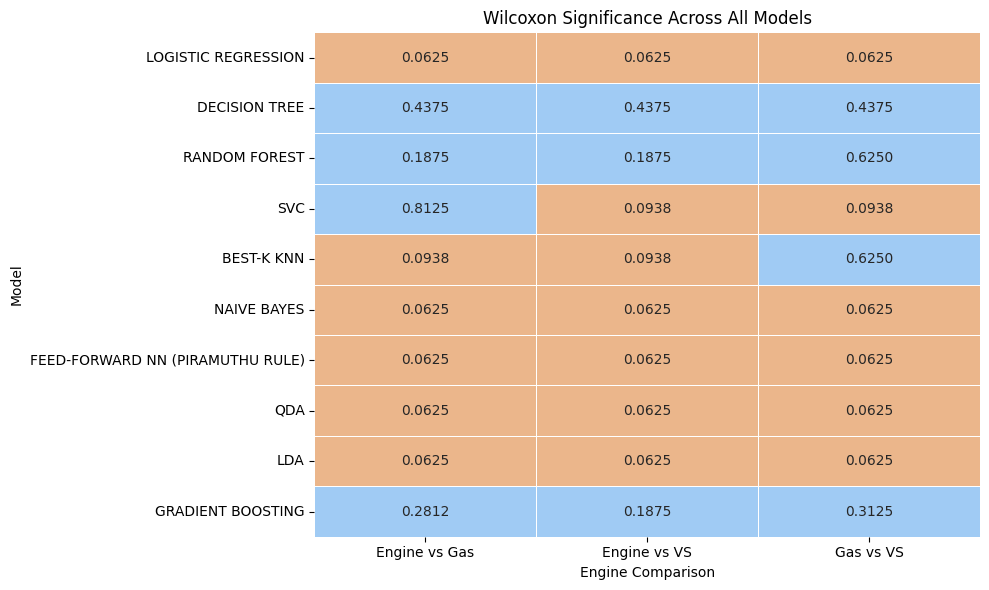

                                 Engine vs Gas Engine vs VS Gas vs VS
LOGISTIC REGRESSION                     0.0625       0.0625    0.0625
DECISION TREE                           0.4375       0.4375    0.4375
RANDOM FOREST                           0.1875       0.1875     0.625
SVC                                     0.8125      0.09375   0.09375
BEST-K KNN                             0.09375      0.09375     0.625
NAIVE BAYES                             0.0625       0.0625    0.0625
FEED-FORWARD NN (PIRAMUTHU RULE)        0.0625       0.0625    0.0625
QDA                                     0.0625       0.0625    0.0625
LDA                                     0.0625       0.0625    0.0625
GRADIENT BOOSTING                      0.28125       0.1875    0.3125


In [137]:
wilcoxon_matrix = wilcoxon_heatmap_all_models(
    engines_1_results_long,
    engines_2_results_long,
    engines_3_results_long,
    alpha=0.10
)

print(wilcoxon_matrix)


In [ ]:
def plot_cv_distributions_separate(eng1, eng2, eng3, baseline=0.751):
    engines = {
        "Engine-Only": eng1,
        "Gas-Only": eng2,
        "Variable Selection": eng3
    }

    palette = sns.color_palette("Set2", 1)[0]

    fig, axes = plt.subplots(3, 1, figsize=(10,15), sharey=True)

    for ax, (engine_name, eng_data) in zip(axes, engines.items()):
        rows = []
        for model, scores in eng_data.items():
            for s in scores:
                rows.append({"Model": model, "F1": s})

        df = pd.DataFrame(rows)

        # --- filter out models with mean F1 < 0.7 ---
        model_means = df.groupby("Model")["F1"].mean()
        keep_models = model_means[model_means >= 0.7].index
        df = df[df["Model"].isin(keep_models)]

        sns.boxplot(
            data=df,
            x="Model",
            y="F1",
            color=palette,
            ax=ax
        )

        # orange baseline line
        ax.axhline(baseline, color="orange", linestyle="--", linewidth=2)

        ax.set_title(f"Cross-Validation F1 — {engine_name}")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


    fig.tight_layout()
    plt.show()


C:\Users\nicol\AppData\Local\Temp\ipykernel_36664\4248136307.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
C:\Users\nicol\AppData\Local\Temp\ipykernel_36664\4248136307.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
C:\Users\nicol\AppData\Local\Temp\ipykernel_36664\4248136307.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


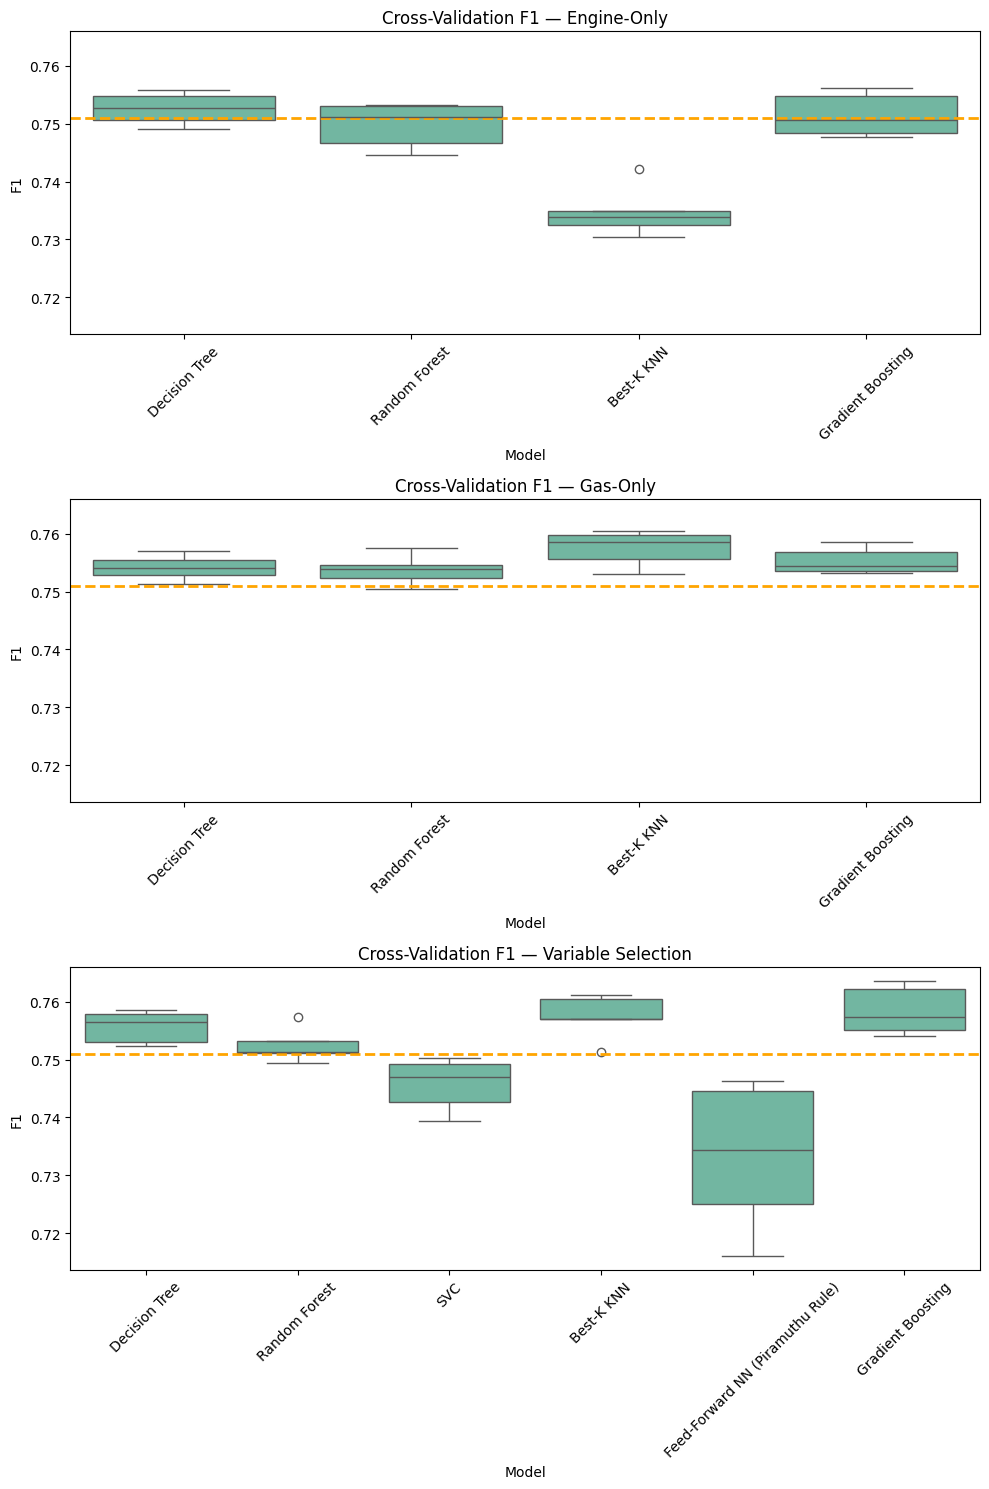

In [147]:
plot_cv_distributions_separate(
    engines_1_results_long,
    engines_2_results_long,
    engines_3_results_long,
    baseline=0.751
)
